Notebook 11 — Final Results Synthesis


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


Mounted at /content/drive


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AI_Trading_Dissertation"
FINAL_PROJECT_PATH = PROJECT_PATH + "/Final_Project"

RESULTS_PATH = FINAL_PROJECT_PATH + "/04_Results"
FINAL_TABLES_PATH = RESULTS_PATH + "/Final_Tables"
FIGURES_PATH = FINAL_PROJECT_PATH + "/05_Figures"
SPLITS_PATH = FINAL_PROJECT_PATH + "/02_Data/Splits"

os.makedirs(FINAL_TABLES_PATH, exist_ok=True)
os.makedirs(FIGURES_PATH, exist_ok=True)

PRIMARY_COST_BPS = 5

SECTOR = {
    "Eicher_Motors": "Automobile", "Mahindra_and_Mahindra": "Automobile",
    "HDFCB": "Banking", "ICICIBC": "Banking",
    "ONGC": "Energy", "Reliance": "Energy",
    "Hindustan_Unilever": "FMCG", "ITC": "FMCG",
    "INFOSYS": "IT", "TCS": "IT",
}
NICE = {
    "Eicher_Motors": "Eicher Motors", "Mahindra_and_Mahindra": "M&M",
    "HDFCB": "HDFC Bank", "ICICIBC": "ICICI Bank", "ONGC": "ONGC",
    "Reliance": "Reliance", "Hindustan_Unilever": "HUL", "ITC": "ITC",
    "INFOSYS": "Infosys", "TCS": "TCS",
}

def load(name, required=False):
    p = os.path.join(RESULTS_PATH, name)
    if os.path.exists(p):
        print(f"  loaded  {name}")
        return pd.read_csv(p)
    p2 = os.path.join(FINAL_TABLES_PATH, name)
    if os.path.exists(p2):
        print(f"  loaded  {name}  (Final_Tables)")
        return pd.read_csv(p2)
    if required:
        raise FileNotFoundError(f"Required file missing: {name}")
    print(f"  MISSING {name}  (skipped)")
    return None

print("Loading saved results:\n")
clf_tree     = load("Model_Metrics_AllStocks.csv", required=True)
clf_tuned    = load("Tuned_Metrics_AllStocks.csv")
clf_dl_v2    = load("DL_Metrics_AllStocks_v2.csv")
clf_dl_v1    = load("DL_Metrics_AllStocks.csv")
bt_thresh    = load("Backtest_Thresholded_Test.csv")
bt_orig      = load("Backtest_Results_Full.csv", required=True)
bt_dl        = load("Backtest_DL_Full_v2.csv")
planned      = load("Table9b_Planned_Comparisons.csv")
feat_imp     = load("Feature_Importances_Averaged.csv")
regime_clf   = load("Regime_Classification.csv")
ret_sig      = load("Table10_Return_Significance.csv")


Loading saved results:

  loaded  Model_Metrics_AllStocks.csv
  loaded  Tuned_Metrics_AllStocks.csv
  loaded  DL_Metrics_AllStocks_v2.csv
  loaded  DL_Metrics_AllStocks.csv
  loaded  Backtest_Thresholded_Test.csv
  loaded  Backtest_Results_Full.csv
  loaded  Backtest_DL_Full_v2.csv
  loaded  Table9b_Planned_Comparisons.csv  (Final_Tables)
  loaded  Feature_Importances_Averaged.csv
  loaded  Regime_Classification.csv
  loaded  Table10_Return_Significance.csv  (Final_Tables)


TABLE 1 — Classification performance, all models


In [ ]:
frames = [clf_tree[["Stock", "Model", "Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro", "Traded_Accuracy"]]]

if clf_dl_v2 is not None:
    frames.append(clf_dl_v2[["Stock", "Model", "Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro", "Traded_Accuracy"]])

all_clf = pd.concat(frames, ignore_index=True)

table1 = (
    all_clf.groupby("Model")[["Accuracy", "Precision_Macro", "Recall_Macro", "F1_Macro", "Traded_Accuracy"]]
    .mean().round(4).sort_values("F1_Macro", ascending=False)
)

rand_acc = table1.loc["Baseline_Random", "Accuracy"]
table1["Acc_vs_Chance_pp"] = ((table1["Accuracy"] - rand_acc) * 100).round(2)

table1.to_csv(os.path.join(FINAL_TABLES_PATH, "T1_Classification_Final.csv"))
print("TABLE 1 — Classification performance (mean across 10 stocks)\n")
display(table1)

per_stock_f1 = all_clf.pivot_table(index="Stock", columns="Model", values="F1_Macro")
order = [m for m in ["Baseline_Random", "Baseline_Majority", "Baseline_Momentum",
                     "RandomForest", "XGBoost", "LSTM", "Transformer"] if m in per_stock_f1.columns]
per_stock_f1 = per_stock_f1[order]
per_stock_f1.to_csv(os.path.join(FINAL_TABLES_PATH, "T1b_F1_By_Stock.csv"))

print("\nBest model per stock:")
display(per_stock_f1.idxmax(axis=1).value_counts())


TABLE 1 — Classification performance (mean across 10 stocks)



,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Traded_Accuracy,Acc_vs_Chance_pp
Model,,,,,,
RandomForest,0.3938,0.3956,0.3983,0.3841,0.3985,5.48
XGBoost,0.3892,0.3978,0.3786,0.3732,0.3816,5.02
Baseline_Random,0.3390,0.3346,0.3346,0.3345,0.3619,0.00
LSTM,0.3664,0.3725,0.3833,0.3254,0.4037,2.74
Transformer,0.3606,0.3744,0.3811,0.3092,0.4063,2.16
Baseline_Momentum,0.3391,0.2841,0.3157,0.2815,0.3496,0.01
Baseline_Majority,0.3604,0.1201,0.3333,0.1766,0.3604,2.14



Best model per stock:


,count
RandomForest,8
XGBoost,2


**Note the ordering.** Both deep learning models score *below* the random baseline on macro F1 while scoring *above* it on accuracy. That is not a contradiction — macro F1 averages across all three classes equally, so a model that neglects the Hold class is penalised heavily even when its Buy/Sell calls are good. Their traded accuracy (the accuracy of the trades they actually take) is the highest of any model.

## TABLE 2 — Planned-comparison significance tests

Seven contrasts, each answering a pre-stated research question, Holm-corrected within the family.

**Why not all pairs.** With n = 10 the Wilcoxon signed-rank test has a floor of p = 2/2¹⁰ = 0.00195. Correcting across all 55 model pairs pushes the smallest attainable adjusted p-value to 0.107, so no result can reach significance even in principle. Planned comparisons keep the test informative.

In [ ]:
if planned is not None:
    t2 = planned[["Question", "Model_A", "Mean_A", "Model_B", "Mean_B",
                  "Mean_Diff", "A_wins", "Wilcoxon_p", "p_holm", "Cohens_d", "Significant_5pct"]]
    t2.to_csv(os.path.join(FINAL_TABLES_PATH, "T2_Planned_Comparisons.csv"), index=False)
    print("TABLE 2 — Planned comparisons\n")
    display(t2)
    print(f"\nSignificant: {int(planned['Significant_5pct'].sum())} of {len(planned)}")
else:
    print("Planned comparisons not found - run the Part C cell in Notebook 09 first.")


TABLE 2 — Planned comparisons



,Question,Model_A,Mean_A,Model_B,Mean_B,Mean_Diff,A_wins,Wilcoxon_p,p_holm,Cohens_d,Significant_5pct
0,Q1 Does ML beat chance?,RandomForest,0.3841,Baseline_Random,0.3345,0.0496,10,0.00195,0.01365,3.296,True
1,Q1 Does ML beat a trivial rule?,RandomForest,0.3841,Baseline_Momentum,0.2815,0.1026,10,0.00195,0.01365,8.182,True
2,Q2 Which tree ensemble?,RandomForest,0.3841,XGBoost,0.3732,0.0109,8,0.04883,0.09766,0.657,False
3,Q3 Trees vs recurrent,RandomForest,0.3841,LSTM_v2,0.3254,0.0587,9,0.00391,0.01955,0.845,True
4,Q3 Trees vs attention,RandomForest,0.3841,Transformer_v2,0.3092,0.0749,9,0.00391,0.01955,0.919,True
5,Q4 Which DL architecture?,LSTM_v2,0.3254,Transformer_v2,0.3092,0.0162,8,0.04883,0.09766,0.694,False
6,Q5 Did tuning help?,RandomForest,0.3841,RandomForest_tuned,0.3748,0.0093,9,0.01367,0.04101,0.919,True



Significant: 5 of 7


## TABLE 3 — Trading performance and break-even costs

In [ ]:
bh = bt_orig[bt_orig["Cost_BPS"] == PRIMARY_COST_BPS]["BuyHold_Return"].mean()

rows = []

# every-bar variants
for model in ["Baseline_Random", "Baseline_Majority", "Baseline_Momentum", "RandomForest", "XGBoost"]:
    sub = bt_orig[(bt_orig["Model"] == model) & (bt_orig["Cost_BPS"] == PRIMARY_COST_BPS)]
    if len(sub) == 0:
        continue
    series = bt_orig[bt_orig["Model"] == model].groupby("Cost_BPS")["Total_Return"].mean() * 100
    rows.append({"Model": model, "Variant": "Every bar",
                 "Ret_0bps_%": round(series.get(0, np.nan), 2),
                 "Ret_5bps_%": round(series.get(5, np.nan), 2),
                 "MaxDD_%": round(sub["Max_Drawdown"].mean() * 100, 2),
                 "Turnover": round(sub["Total_Cost_Paid"].mean() / (PRIMARY_COST_BPS / 10000), 0),
                 "InMkt_%": round(sub["Time_In_Market"].mean() * 100, 1)})

# thresholded tree models
if bt_thresh is not None:
    for model in ["RandomForest", "XGBoost"]:
        sub = bt_thresh[(bt_thresh["Model"] == model) & (bt_thresh["Cost_BPS"] == PRIMARY_COST_BPS)]
        if len(sub) == 0:
            continue
        series = bt_thresh[bt_thresh["Model"] == model].groupby("Cost_BPS")["Total_Return"].mean() * 100
        rows.append({"Model": model, "Variant": "Thresholded",
                     "Ret_0bps_%": round(series.get(0, np.nan), 2),
                     "Ret_5bps_%": round(series.get(5, np.nan), 2),
                     "MaxDD_%": round(sub["Max_Drawdown"].mean() * 100, 2),
                     "Turnover": round(sub["Turnover_Units"].mean(), 0),
                     "InMkt_%": round(sub["Time_In_Market"].mean() * 100, 1)})

# thresholded deep learning
if bt_dl is not None:
    for model in ["LSTM", "Transformer"]:
        sub = bt_dl[(bt_dl["Model"] == model) & (bt_dl["Variant"] == "Thresholded") & (bt_dl["Cost_BPS"] == PRIMARY_COST_BPS)]
        if len(sub) == 0:
            continue
        series = bt_dl[(bt_dl["Model"] == model) & (bt_dl["Variant"] == "Thresholded")].groupby("Cost_BPS")["Total_Return"].mean() * 100
        rows.append({"Model": model, "Variant": "Thresholded",
                     "Ret_0bps_%": round(series.get(0, np.nan), 2),
                     "Ret_5bps_%": round(series.get(5, np.nan), 2),
                     "MaxDD_%": round(sub["Max_Drawdown"].mean() * 100, 2),
                     "Turnover": round(sub["Turnover_Units"].mean(), 0),
                     "InMkt_%": round(sub["Time_In_Market"].mean() * 100, 1)})

table3 = pd.DataFrame(rows)


def breakeven(series_pct, benchmark_pct):
    costs = series_pct.index.values.astype(float); vals = series_pct.values
    above = vals > benchmark_pct
    if not above.any(): return np.nan
    if above.all(): return float(costs.max())
    last_ok = costs[above].max()
    worse = costs[~above & (costs > last_ok)]
    if len(worse) == 0: return float(last_ok)
    lo, hi = last_ok, worse.min()
    v_lo, v_hi = vals[costs == lo][0], vals[costs == hi][0]
    frac = (v_lo - benchmark_pct) / (v_lo - v_hi) if v_lo != v_hi else 0
    return round(lo + frac * (hi - lo), 2)


be_vals = []
for _, r in table3.iterrows():
    if r["Variant"] == "Every bar":
        src = bt_orig[bt_orig["Model"] == r["Model"]]
    elif r["Model"] in ("LSTM", "Transformer"):
        src = bt_dl[(bt_dl["Model"] == r["Model"]) & (bt_dl["Variant"] == "Thresholded")]
    else:
        src = bt_thresh[bt_thresh["Model"] == r["Model"]]
    be_vals.append(breakeven(src.groupby("Cost_BPS")["Total_Return"].mean() * 100, bh * 100))

table3["Breakeven_bps"] = be_vals
table3 = table3.sort_values("Breakeven_bps", ascending=False, na_position="last").reset_index(drop=True)

table3.to_csv(os.path.join(FINAL_TABLES_PATH, "T3_Trading_Breakeven.csv"), index=False)
print(f"TABLE 3 — Trading performance   (buy & hold = {bh*100:.2f}%)\n")
display(table3)
print("\nBreak-even = the transaction cost at which the strategy stops beating buy & hold.")
print("NaN = never beats the benchmark at any cost level tested.")


TABLE 3 — Trading performance   (buy & hold = -3.33%)



,Model,Variant,Ret_0bps_%,Ret_5bps_%,MaxDD_%,Turnover,InMkt_%,Breakeven_bps
0,Transformer,Thresholded,1.92,-5.92,-12.59,169.0,14.6,3.28
1,RandomForest,Thresholded,6.09,-9.83,-22.19,328.0,28.2,2.85
2,LSTM,Thresholded,0.43,-7.03,-13.76,153.0,13.2,2.44
3,RandomForest,Every bar,100.93,-78.71,-80.60,4670.0,65.8,1.72
4,XGBoost,Every bar,54.32,-91.13,-91.46,5751.0,82.8,1.09
5,XGBoost,Thresholded,-2.08,-40.49,-50.33,995.0,89.9,0.14
6,Baseline_Random,Every bar,-0.67,-99.87,-99.87,13328.0,72.0,0.06
7,Baseline_Majority,Every bar,-6.24,-6.29,-35.23,1.0,100.0,NaN
8,Baseline_Momentum,Every bar,-62.26,-99.98,-99.98,15224.0,94.5,NaN



Break-even = the transaction cost at which the strategy stops beating buy & hold.
NaN = never beats the benchmark at any cost level tested.


## TABLE 4 — Classification rank versus economic rank

If statistical skill and economic value were the same thing, these two rankings would match. They do not.

In [ ]:
thr = table3[table3["Variant"] == "Thresholded"].copy()
clf_means = table1["F1_Macro"]

t4 = thr[["Model", "Ret_0bps_%", "Ret_5bps_%", "Breakeven_bps", "Turnover", "InMkt_%"]].copy()
t4["F1_Macro"] = t4["Model"].map(clf_means)
t4 = t4.dropna(subset=["F1_Macro"])

t4["Rank_by_F1"] = t4["F1_Macro"].rank(ascending=False).astype(int)
t4["Rank_by_Breakeven"] = t4["Breakeven_bps"].rank(ascending=False).astype(int)
t4["Rank_Change"] = t4["Rank_by_F1"] - t4["Rank_by_Breakeven"]

t4 = t4.sort_values("Rank_by_Breakeven")[
    ["Model", "F1_Macro", "Rank_by_F1", "Breakeven_bps", "Rank_by_Breakeven", "Rank_Change", "Turnover", "InMkt_%"]
]

t4.to_csv(os.path.join(FINAL_TABLES_PATH, "T4_Classification_vs_Economics.csv"), index=False)
print("TABLE 4 — Ranked by classification skill vs ranked by economic viability\n")
display(t4)

if len(t4) > 1:
    rho = t4["F1_Macro"].corr(t4["Breakeven_bps"], method="spearman")
    print(f"\nSpearman rank correlation between F1 and break-even cost: {rho:+.3f}")
    print("A value near zero or negative means classification skill does not predict economic value.")


TABLE 4 — Ranked by classification skill vs ranked by economic viability



,Model,F1_Macro,Rank_by_F1,Breakeven_bps,Rank_by_Breakeven,Rank_Change,Turnover,InMkt_%
0,Transformer,0.3092,4,3.28,1,3,169.0,14.6
1,RandomForest,0.3841,1,2.85,2,-1,328.0,28.2
2,LSTM,0.3254,3,2.44,3,0,153.0,13.2
5,XGBoost,0.3732,2,0.14,4,-2,995.0,89.9



Spearman rank correlation between F1 and break-even cost: -0.400
A value near zero or negative means classification skill does not predict economic value.


## TABLE 5 — Per-stock and per-sector breakdown

In [ ]:
best_clf = clf_tree[clf_tree["Model"] == "RandomForest"][["Stock", "Accuracy", "F1_Macro"]].copy()

if bt_thresh is not None:
    bt_rf = bt_thresh[(bt_thresh["Model"] == "RandomForest") & (bt_thresh["Cost_BPS"] == PRIMARY_COST_BPS)][
        ["Stock", "Total_Return", "Max_Drawdown", "BuyHold_Return", "Turnover_Units", "Time_In_Market"]]
    t5 = best_clf.merge(bt_rf, on="Stock", how="left")
else:
    t5 = best_clf

t5["Sector"] = t5["Stock"].map(SECTOR)
t5["Name"] = t5["Stock"].map(NICE)

for c in ["Total_Return", "Max_Drawdown", "BuyHold_Return"]:
    if c in t5.columns:
        t5[c] = (t5[c] * 100).round(2)

if "Total_Return" in t5.columns:
    t5["Beat_BH"] = np.where(t5["Total_Return"] > t5["BuyHold_Return"], "Yes", "No")

cols = [c for c in ["Sector", "Name", "Accuracy", "F1_Macro", "Total_Return",
                    "BuyHold_Return", "Beat_BH", "Max_Drawdown", "Turnover_Units", "Time_In_Market"] if c in t5.columns]
t5 = t5[cols].sort_values(["Sector", "Name"]).reset_index(drop=True)

t5.to_csv(os.path.join(FINAL_TABLES_PATH, "T5_Per_Stock.csv"), index=False)
print("TABLE 5 — Random Forest (thresholded), per stock\n")
display(t5)

num_cols = [c for c in ["Accuracy", "F1_Macro", "Total_Return", "BuyHold_Return"] if c in t5.columns]
sector_tbl = t5.groupby("Sector")[num_cols].mean().round(3)
sector_tbl.to_csv(os.path.join(FINAL_TABLES_PATH, "T5b_Per_Sector.csv"))
print("\nBy sector:\n")
display(sector_tbl)


TABLE 5 — Random Forest (thresholded), per stock



,Sector,Name,Accuracy,F1_Macro,Total_Return,BuyHold_Return,Beat_BH,Max_Drawdown,Turnover_Units,Time_In_Market
0,Automobile,Eicher Motors,0.3940,0.3911,-8.80,60.80,No,-12.65,54.0,0.047
1,Automobile,M&M,0.3940,0.3740,5.38,19.90,No,-16.44,154.0,0.132
2,Banking,HDFC Bank,0.3925,0.3650,-5.45,-10.16,Yes,-11.73,76.0,0.065
3,Banking,ICICI Bank,0.3845,0.3683,0.00,24.20,No,0.00,0.0,0.000
4,Energy,ONGC,0.3974,0.3913,-28.93,-10.72,No,-38.43,661.0,0.567
5,Energy,Reliance,0.4036,0.3998,-10.56,-10.15,No,-21.56,441.0,0.378
6,FMCG,HUL,0.3757,0.3739,9.81,-12.94,Yes,-16.35,417.0,0.358
7,FMCG,ITC,0.3980,0.3977,-12.02,-29.70,Yes,-32.62,625.0,0.537
8,IT,Infosys,0.3978,0.3849,-14.84,-26.43,Yes,-31.28,484.0,0.414
9,IT,TCS,0.4003,0.3949,-32.91,-38.13,Yes,-40.81,371.0,0.318



By sector:



,Accuracy,F1_Macro,Total_Return,BuyHold_Return
Sector,,,,
Automobile,0.394,0.383,-1.710,40.350
Banking,0.388,0.367,-2.725,7.020
Energy,0.400,0.396,-19.745,-10.435
FMCG,0.387,0.386,-1.105,-21.320
IT,0.399,0.390,-23.875,-32.280


## TABLE 6 — Feature importance

In [ ]:
if feat_imp is not None:
    rf_imp = feat_imp[feat_imp["Model"] == "RandomForest"].nlargest(10, "Importance")[["Feature", "Importance"]]
    rf_imp["Importance"] = rf_imp["Importance"].round(4)
    rf_imp = rf_imp.reset_index(drop=True); rf_imp.index += 1
    rf_imp.to_csv(os.path.join(FINAL_TABLES_PATH, "T6_Feature_Importance.csv"))
    print("TABLE 6 — Top 10 features, Random Forest\n")
    display(rf_imp)

    def family(f):
        if "volume" in f: return "Volume"
        if "volatility" in f or "bandwidth" in f: return "Volatility"
        if "rsi" in f or "macd" in f: return "Momentum oscillator"
        if "sma" in f or "ema" in f or "bb_" in f: return "Trend / price level"
        if "return" in f: return "Return"
        return "Other"

    fam = feat_imp[feat_imp["Model"] == "RandomForest"].copy()
    fam["Family"] = fam["Feature"].apply(family)
    fam_sum = fam.groupby("Family")["Importance"].sum().sort_values(ascending=False).round(4)
    fam_sum.to_csv(os.path.join(FINAL_TABLES_PATH, "T6b_Feature_Families.csv"))
    print("\nBy family:\n")
    display(fam_sum)

    VOL_SHARE = fam_sum.get("Volume", 0) + fam_sum.get("Volatility", 0)
    print(f"\nVolume + Volatility = {VOL_SHARE:.1%} of total importance")
else:
    VOL_SHARE = np.nan
    print("Feature importances not found.")


TABLE 6 — Top 10 features, Random Forest



,Feature,Importance
1,volume_relative,0.1984
2,volatility_20,0.1641
3,bb_bandwidth,0.0685
4,bb_percent_b,0.0503
5,volume_avg_20,0.0459
6,macd_signal,0.0378
7,rsi_14,0.0372
8,macd_line,0.0372
9,macd_hist,0.0359
10,log_return_1,0.0341



By family:



,Importance
Family,
Trend / price level,0.3076
Volume,0.2443
Volatility,0.2325
Momentum oscillator,0.1481
Return,0.0675



Volume + Volatility = 47.7% of total importance


## TABLE 7 — Volatility regime analysis

In [ ]:
if regime_clf is not None:
    t7 = (regime_clf.groupby(["Model", "Regime"])[["Accuracy", "F1_Macro", "Mean_VIX"]]
          .mean().round(4).unstack())
    t7.to_csv(os.path.join(FINAL_TABLES_PATH, "T7_Regime.csv"))
    print("TABLE 7 — Performance by volatility regime\n")
    display(t7)
    print("\nDifferences are small across all models. The target threshold is volatility-adaptive")
    print("(0.5 x rolling 20-bar volatility), so regime effects are largely neutralised by design -")
    print("the bar for calling a Buy rises automatically when the market is turbulent.")
else:
    print("Regime results not found - run Notebook 10.")


TABLE 7 — Performance by volatility regime



Accuracy         F1_Macro         Mean_VIX         
Regime            High VIX Low VIX High VIX Low VIX High VIX  Low VIX
Model                                                                
Baseline_Momentum   0.3404  0.3378   0.2816  0.2813  16.4368  12.0464
Baseline_Random     0.3377  0.3403   0.3338  0.3350  16.4368  12.0464
RandomForest        0.3889  0.3986   0.3787  0.3836  16.4368  12.0464
XGBoost             0.3877  0.3908   0.3778  0.3652  16.4368  12.0464


Differences are small across all models. The target threshold is volatility-adaptive
(0.5 x rolling 20-bar volatility), so regime effects are largely neutralised by design -
the bar for calling a Buy rises automatically when the market is turbulent.


## FIGURE 1 — Cost sensitivity, all models

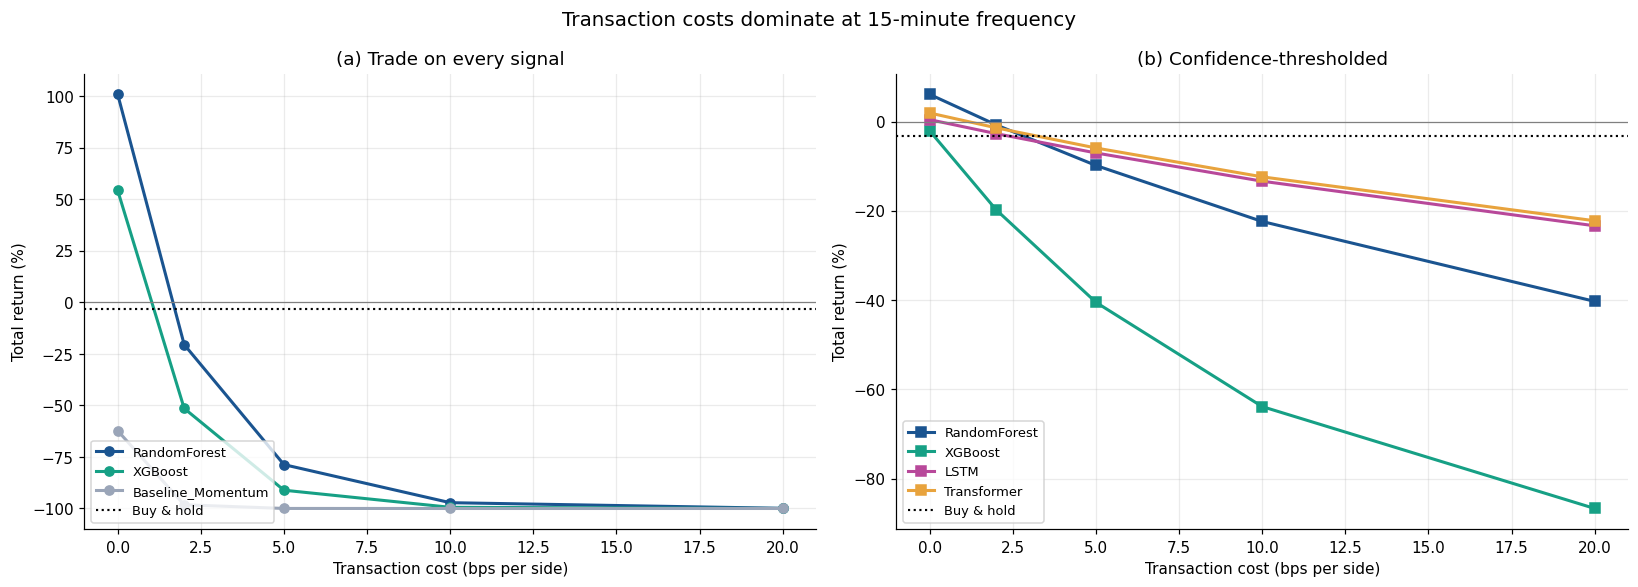

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))

palette = {"RandomForest": "#1a5490", "XGBoost": "#16a085",
           "LSTM": "#b8489a", "Transformer": "#e8a33d",
           "Baseline_Momentum": "#9aa5b8"}

ax = axes[0]
for model, colour in palette.items():
    sub = bt_orig[bt_orig["Model"] == model]
    if len(sub) == 0:
        continue
    s = sub.groupby("Cost_BPS")["Total_Return"].mean() * 100
    ax.plot(s.index, s.values, marker="o", linewidth=2, color=colour, label=model)
ax.axhline(bh * 100, color="black", linestyle=":", linewidth=1.4, label="Buy & hold")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Transaction cost (bps per side)"); ax.set_ylabel("Total return (%)")
ax.set_title("(a) Trade on every signal"); ax.legend(fontsize=8.5, loc="lower left")

ax = axes[1]
for model, colour in palette.items():
    if model.startswith("Baseline"):
        continue
    if model in ("LSTM", "Transformer") and bt_dl is not None:
        sub = bt_dl[(bt_dl["Model"] == model) & (bt_dl["Variant"] == "Thresholded")]
    elif bt_thresh is not None:
        sub = bt_thresh[bt_thresh["Model"] == model]
    else:
        continue
    if len(sub) == 0:
        continue
    s = sub.groupby("Cost_BPS")["Total_Return"].mean() * 100
    ax.plot(s.index, s.values, marker="s", linewidth=2, color=colour, label=model)
ax.axhline(bh * 100, color="black", linestyle=":", linewidth=1.4, label="Buy & hold")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Transaction cost (bps per side)"); ax.set_ylabel("Total return (%)")
ax.set_title("(b) Confidence-thresholded"); ax.legend(fontsize=8.5, loc="lower left")

plt.suptitle("Transaction costs dominate at 15-minute frequency", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "F1_cost_sensitivity_final.png"), dpi=200, bbox_inches="tight")
plt.show()


## FIGURE 2 — Classification skill versus economic viability


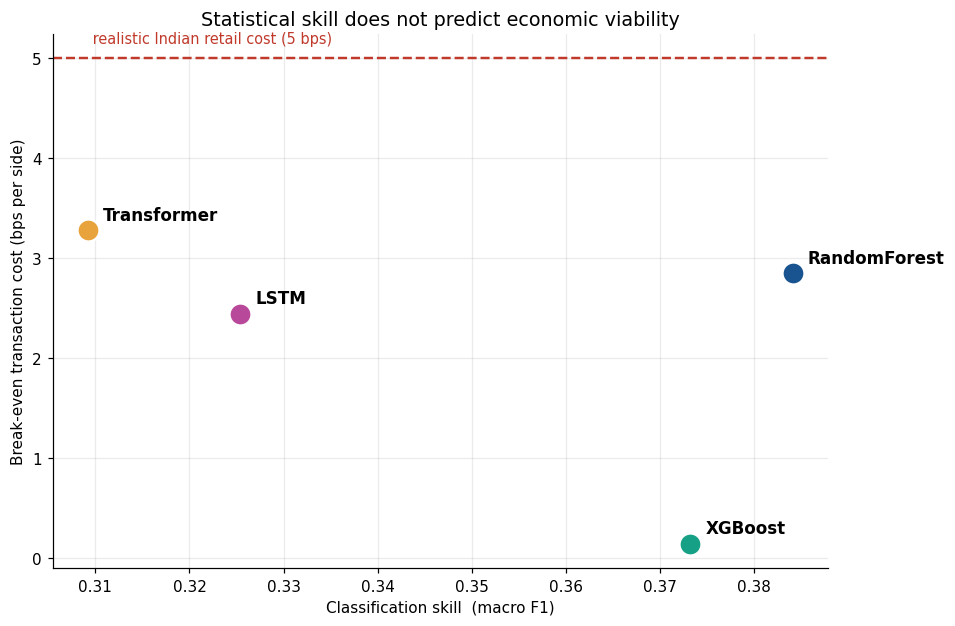

In [ ]:
fig, ax = plt.subplots(figsize=(8.8, 5.8))

for _, r in t4.iterrows():
    be = r["Breakeven_bps"] if not pd.isna(r["Breakeven_bps"]) else 0
    colour = palette.get(r["Model"], "#9aa5b8")
    ax.scatter(r["F1_Macro"], be, s=210, color=colour, zorder=3, edgecolor="white", linewidth=1.6)
    ax.annotate(r["Model"], (r["F1_Macro"], be), xytext=(10, 7),
                textcoords="offset points", fontsize=11, fontweight="bold")

ax.axhline(PRIMARY_COST_BPS, color="#c0392b", linestyle="--", linewidth=1.6)
ax.text(t4["F1_Macro"].min(), PRIMARY_COST_BPS + 0.12,
        " realistic Indian retail cost (5 bps)", color="#c0392b", fontsize=9.5, va="bottom")

ax.set_xlabel("Classification skill  (macro F1)")
ax.set_ylabel("Break-even transaction cost (bps per side)")
ax.set_title("Statistical skill does not predict economic viability", fontsize=12.5)

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "F2_skill_vs_viability_final.png"), dpi=200, bbox_inches="tight")
plt.show()


## FIGURE 3 — Model comparison panel

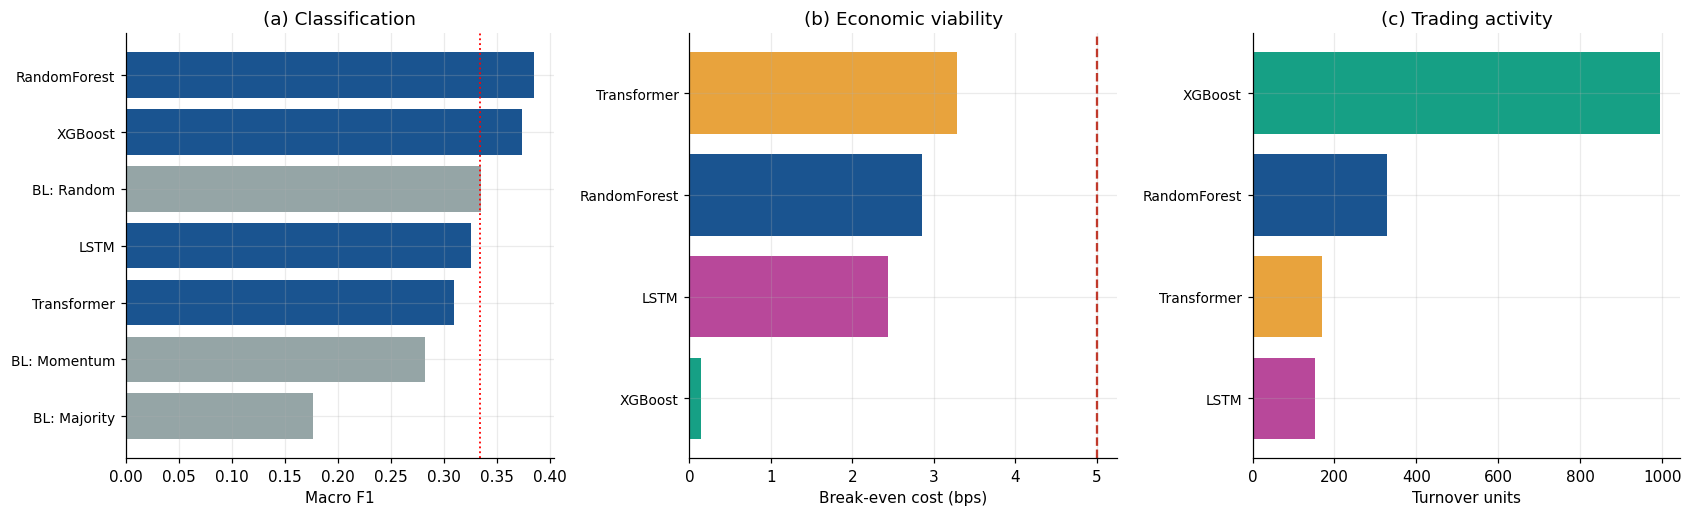

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8))

ax = axes[0]
o = table1.sort_values("F1_Macro").index
cols = ["#95a5a6" if "Baseline" in m else "#1a5490" for m in o]
ax.barh(range(len(o)), table1.loc[o, "F1_Macro"], color=cols)
ax.set_yticks(range(len(o)))
ax.set_yticklabels([m.replace("Baseline_", "BL: ") for m in o], fontsize=9)
ax.set_xlabel("Macro F1"); ax.set_title("(a) Classification")
ax.axvline(1/3, color="red", linestyle=":", linewidth=1.2)

ax = axes[1]
if len(t4):
    d = t4.sort_values("Breakeven_bps")
    ax.barh(range(len(d)), d["Breakeven_bps"], color=[palette.get(m, "#9aa5b8") for m in d["Model"]])
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d["Model"], fontsize=9)
    ax.axvline(PRIMARY_COST_BPS, color="#c0392b", linestyle="--", linewidth=1.5)
    ax.set_xlabel("Break-even cost (bps)"); ax.set_title("(b) Economic viability")

ax = axes[2]
if len(t4):
    d = t4.sort_values("Turnover")
    ax.barh(range(len(d)), d["Turnover"], color=[palette.get(m, "#9aa5b8") for m in d["Model"]])
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d["Model"], fontsize=9)
    ax.set_xlabel("Turnover units"); ax.set_title("(c) Trading activity")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_PATH, "F3_model_comparison_final.png"), dpi=200, bbox_inches="tight")
plt.show()


## FIGURE 4 — Per-stock performance

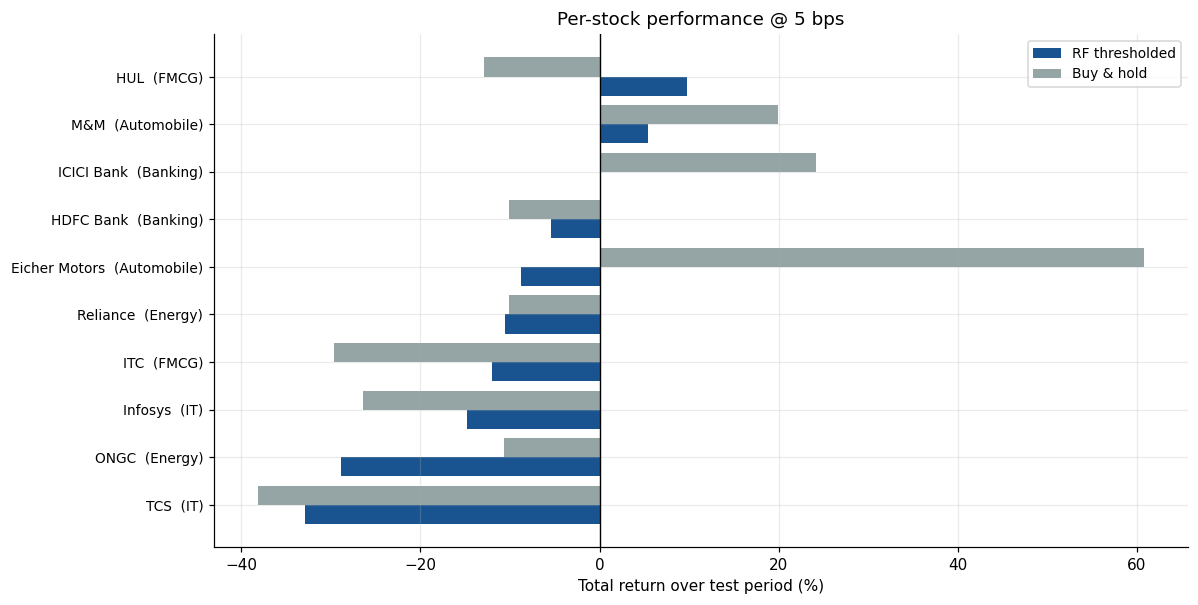

In [ ]:
if "Total_Return" in t5.columns:
    fig, ax = plt.subplots(figsize=(11, 5.6))
    d = t5.sort_values("Total_Return")
    y = np.arange(len(d)); w = 0.4
    ax.barh(y - w/2, d["Total_Return"], w, label="RF thresholded", color="#1a5490")
    ax.barh(y + w/2, d["BuyHold_Return"], w, label="Buy & hold", color="#95a5a6")
    ax.axvline(0, color="black", linewidth=0.9)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{n}  ({s})" for n, s in zip(d["Name"], d["Sector"])], fontsize=9)
    ax.set_xlabel("Total return over test period (%)")
    ax.set_title(f"Per-stock performance @ {PRIMARY_COST_BPS} bps", fontsize=12)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES_PATH, "F4_per_stock_final.png"), dpi=200, bbox_inches="tight")
    plt.show()


## Main SUMMARY


In [ ]:
train_s = pd.read_parquet(os.path.join(SPLITS_PATH, "Reliance_train.parquet"))
test_s = pd.read_parquet(os.path.join(SPLITS_PATH, "Reliance_test.parquet"))

L = ["=" * 78, "MASTER KEY NUMBERS", "=" * 78, "", "DATA"]
L += [
    "  10 stocks, 5 sectors, 2 per sector",
    "  15-minute bars, Bloomberg terminal (timestamps in GST / UTC+4)",
    "  Jan 2016 - Jul 2026,  ~730,000 bars after cleaning",
    "  22 engineered features",
    f"  Train: 2016-01 to {train_s['datetime'].max().date()}   ({len(train_s):,} bars/stock)",
    f"  Test:  {test_s['datetime'].min().date()} to {test_s['datetime'].max().date()}   ({len(test_s):,} bars/stock)",
    "  Chronological 80/20 split, never shuffled",
    "",
    "CLASSIFICATION  (macro F1, mean of 10 stocks)",
]
for m, v in table1["F1_Macro"].items():
    L.append(f"  {m:22s} {v:.4f}")

L += ["", "SIGNIFICANCE  (planned comparisons, Holm-corrected)"]
if planned is not None:
    for _, r in planned.iterrows():
        mark = "*" if r["Significant_5pct"] else " "
        L.append(f" {mark} {r['Model_A']:18s} vs {r['Model_B']:18s} "
                 f"diff {r['Mean_Diff']:+.4f}  wins {r['A_wins']}/10  "
                 f"Holm p={r['p_holm']:.4f}  d={r['Cohens_d']:+.2f}")
    L.append(f"   ({int(planned['Significant_5pct'].sum())} of {len(planned)} significant; * = significant)")

L += ["", f"TRADING  (thresholded, {PRIMARY_COST_BPS} bps/side; buy & hold = {bh*100:+.2f}%)"]
for _, r in table3[table3["Variant"] == "Thresholded"].iterrows():
    be = f"{r['Breakeven_bps']:.2f} bps" if not pd.isna(r["Breakeven_bps"]) else "never beats B&H"
    L.append(f"  {r['Model']:16s} 0bps {r['Ret_0bps_%']:>7.2f}%   5bps {r['Ret_5bps_%']:>7.2f}%   "
             f"break-even {be}   turnover {r['Turnover']:.0f}")

rf_e = table3[(table3["Model"] == "RandomForest") & (table3["Variant"] == "Every bar")]
rf_t = table3[(table3["Model"] == "RandomForest") & (table3["Variant"] == "Thresholded")]
if len(rf_e) and len(rf_t):
    e, t = rf_e.iloc[0], rf_t.iloc[0]
    L += ["", "THE TURNOVER MECHANISM  (Random Forest)",
          f"  Every bar    : {e['Ret_0bps_%']:+.2f}% at 0bps -> {e['Ret_5bps_%']:+.2f}% at 5bps   "
          f"turnover {e['Turnover']:.0f}   in-market {e['InMkt_%']:.0f}%",
          f"  Thresholded  : {t['Ret_0bps_%']:+.2f}% at 0bps -> {t['Ret_5bps_%']:+.2f}% at 5bps   "
          f"turnover {t['Turnover']:.0f}   in-market {t['InMkt_%']:.0f}%",
          f"  Turnover reduction: {e['Turnover']/max(t['Turnover'],1):.0f}x    "
          f"return improvement: {t['Ret_5bps_%']-e['Ret_5bps_%']:+.1f} pp",
          "  Config: confidence >= 0.50, minimum hold 26 bars (one trading day),",
          "          selected on a validation split and applied once to test."]

L += ["", "FEATURES"]
if not np.isnan(VOL_SHARE):
    L.append(f"  Volume + volatility = {VOL_SHARE:.0%} of total importance")
if feat_imp is not None:
    top = feat_imp[feat_imp["Model"] == "RandomForest"].nlargest(3, "Importance")
    for _, r in top.iterrows():
        L.append(f"  {r['Feature']:20s} {r['Importance']:.3f}")

L += ["", "ROBUSTNESS",
      "  Volatility regimes : no material difference (target is volatility-adaptive by design)",
      "  Hyperparameter tuning: did NOT improve on defaults (RF 0.3841 -> 0.3748, worse on 9/10)",
      "  Statistical power  : n=10 detects only large effects (80% power at d=1.0)",
      "  Backtest validated : oracle, inverse-oracle and always-flat controls all behaved correctly",
      "",
      "HEADLINE",
      "  1. Predictive skill is real and significant - RF beat every baseline on 10/10 stocks",
      "  2. Random Forest significantly outperformed BOTH deep learning architectures",
      "  3. The edge does not survive realistic costs - break-even ~2.85 bps vs ~5 bps actual",
      "  4. Turnover, not accuracy, is the binding constraint",
      "  5. Classification rank and economic rank do not agree",
      "", "=" * 78]

txt = "\n".join(L)
print(txt)

with open(os.path.join(FINAL_TABLES_PATH, "KEY_NUMBERS_MASTER.txt"), "w") as f:
    f.write(txt)
print("\n\nSaved to Final_Tables/KEY_NUMBERS_MASTER.txt")


MASTER KEY NUMBERS

DATA
  10 stocks, 5 sectors, 2 per sector
  15-minute bars, Bloomberg terminal (timestamps in GST / UTC+4)
  Jan 2016 - Jul 2026,  ~730,000 bars after cleaning
  22 engineered features
  Train: 2016-01 to 2024-06-21   (58,432 bars/stock)
  Test:  2024-06-21 to 2026-07-31   (14,609 bars/stock)
  Chronological 80/20 split, never shuffled

CLASSIFICATION  (macro F1, mean of 10 stocks)
  RandomForest           0.3841
  XGBoost                0.3732
  Baseline_Random        0.3345
  LSTM                   0.3254
  Transformer            0.3092
  Baseline_Momentum      0.2815
  Baseline_Majority      0.1766

SIGNIFICANCE  (planned comparisons, Holm-corrected)
 * RandomForest       vs Baseline_Random    diff +0.0496  wins 10/10  Holm p=0.0137  d=+3.30
 * RandomForest       vs Baseline_Momentum  diff +0.1026  wins 10/10  Holm p=0.0137  d=+8.18
   RandomForest       vs XGBoost            diff +0.0109  wins 8/10  Holm p=0.0977  d=+0.66
 * RandomForest       vs LSTM_v2        

In [ ]:
print("TABLES  (04_Results/Final_Tables/)")
for f in sorted(os.listdir(FINAL_TABLES_PATH)):
    print("  ", f)

print("\nFIGURES  (05_Figures/)")
for f in sorted(os.listdir(FIGURES_PATH)):
    if f.endswith(".png"):
        print(f"   {f}  ({os.path.getsize(os.path.join(FIGURES_PATH, f))/1024:.0f} KB)")


TABLES  (04_Results/Final_Tables/)
   F1_AllModels_ByStock.csv
   F1_AllModels_ByStock_Final.csv
   KEY_NUMBERS.txt
   KEY_NUMBERS_FINAL_v2.txt
   KEY_NUMBERS_MASTER.txt
   REGIME_SIGNIFICANCE_SUMMARY.txt
   T1_Classification_Final.csv
   T1b_F1_By_Stock.csv
   T2_Planned_Comparisons.csv
   T3_Trading_Breakeven.csv
   T4_Classification_vs_Economics.csv
   T5_Per_Stock.csv
   T5b_Per_Sector.csv
   T6_Feature_Importance.csv
   T6b_Feature_Families.csv
   T7_Regime.csv
   Table10_Return_Significance.csv
   Table1_Classification.csv
   Table1_Classification_AllModels.csv
   Table1_Classification_Final.csv
   Table2_Trading_Headline.csv
   Table3_Cost_Sensitivity.csv
   Table4_Per_Stock.csv
   Table4b_Per_Sector.csv
   Table5_Feature_Importance.csv
   Table5b_Feature_Families.csv
   Table6_AllModels_Trading_v2.csv
   Table7_Breakeven_AllModels_v2.csv
   Table8_Tuning_Effect.csv
   Table9_Significance_Tests.csv
   Table9b_Planned_Comparisons.csv

FIGURES  (05_Figures/)
   F1_cost_sensitivity